# 🌽 Lesson 10 · Project 3 · Crop Disease Classification

*“A model that is 95 % accurate in the lab and 60 % in the field is not a 95 % model. Let's build one and ask the honest questions.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~170 min | 🟠 Intermediate → Advanced | Day 8–9 | Lessons 05–09 |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Build a **multi-class CNN** for maize-leaf disease images (RGB, channels-last → channels-first!)
- Use **label-preserving augmentation** suited to leaf photos (rotations, flips)
- Perform **rich error analysis**: accuracy vs. disease severity, confusion pairs, per-class recall
- See *where the model looks* with **occlusion sensitivity**
- Design a **confidence-based triage policy** (diagnose / retake photo / refer to an expert)
- Know how to move from this synthetic data to **real data and transfer learning**
- Reflect on **bias, distribution shift and responsible deployment** in agriculture

## 🗺 Roadmap
1. Project brief & honest caveats
2. Explore the data
3. Preprocess (channels!)
4. Baselines: what do pixels alone give us?
5. The CNN
6. Evaluate
7. Severity analysis
8. Where is the model looking?
9. Triage policy
10. Transfer learning & real data
11. Report & stretch goals
12. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
cpu = torch.device('cpu')
dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 📋 1. Project brief: and honest caveats

> **Client.** A cooperative of smallholder maize farmers in Kenya's Rift Valley and an agricultural extension officer who can't visit every farm. Farmers photograph a leaf with a phone; an app suggests *what's wrong*.
> **Your job.** Build the classifier at the heart of that app.

**Classes** (all real maize conditions in East Africa):

| Class | Visual signature | Impact |
|:--|:--|:--|
| `healthy` | Clean green leaf | - |
| `gray_leaf_spot` | Many small **rectangular** tan-grey lesions between veins | Can cut yield substantially in humid areas |
| `northern_leaf_blight` | Few **long cigar-shaped** tan lesions | Severe in cool, humid weather |
| `common_rust` | Many tiny **red-brown pustules** | Usually milder; fungicide may not pay |
| `maize_streak` | Pale-yellow **streaks along** the veins (a virus spread by leafhoppers) | Can devastate a crop; *no cure*: remove plants |

| | |
|:--|:--|
| **Data** | 3,000 synthetic 48×48 RGB leaf images (2,100 train / 450 val / 450 test) generated by `data/build_datasets.py` |
| **Success criteria** | ≥ **85 %** test accuracy · **recall ≥ 70 % on every disease** · a written triage policy · a bias/limitations section · *(stretch: ≥ 90 %, using the ideas in the stretch goals)* |

> ⚠️ **Honest caveat #1: synthetic data.** Our leaves are *simulated*: uniform backgrounds, clean lighting, simplified lesions. Real field photos are messy (hands, shadows, soil, multiple leaves, motion blur, other diseases). Treat this project as practising the **workflow** and the **thinking**, not as agronomy. Section 10 shows how to swap in real photos.
> ⚠️ **Honest caveat #2: the cost of mistakes isn't symmetric.** Calling *maize streak* "healthy" can cost a harvest; calling *healthy* "rust" wastes a spray. Keep that in mind throughout.

---
## 🔭 2. Explore the data

{'x_train': (2100, 48, 48, 3), 'x_val': (450, 48, 48, 3), 'x_test': (450, 48, 48, 3)}
train class counts: {'healthy': np.int64(419), 'gray_leaf_spot': np.int64(435), 'northern_leaf_blight': np.int64(421), 'common_rust': np.int64(427), 'maize_streak': np.int64(398)}


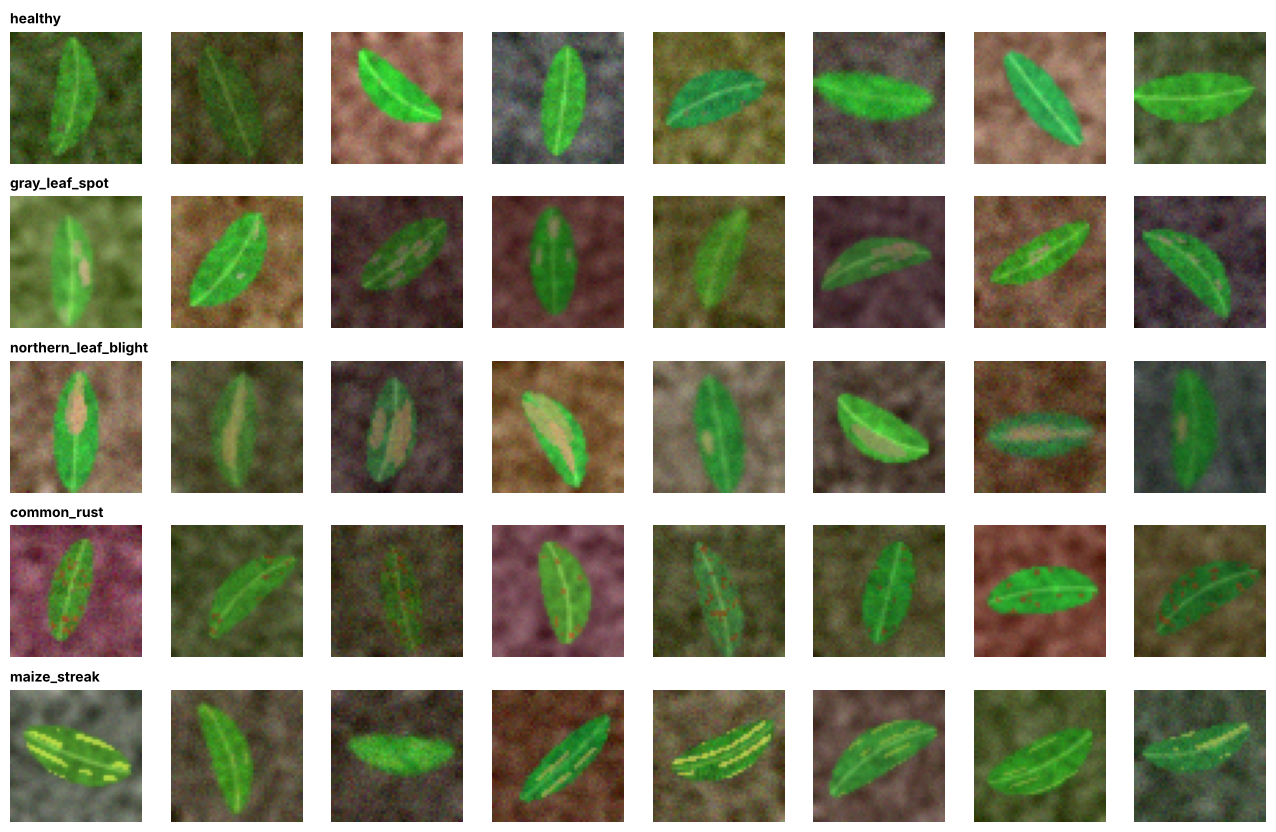

In [2]:
d = dl.load_leaves(); names = dl.LEAF_CLASSES
print({k: v.shape for k, v in d.items() if k.startswith("x_")})
print("train class counts:", dict(zip(names, np.bincount(d["y_train"]))))

fig, axes = plt.subplots(5, 8, figsize=(13, 8.4))
for c in range(5):
    for j, idx in enumerate(np.where(d["y_train"] == c)[0][:8]):
        axes[c, j].imshow(d["x_train"][idx]); axes[c, j].axis("off")
    axes[c, 0].set_title(names[c], loc="left", fontsize=10)
plt.tight_layout(); plt.show()

The generator also recorded each image's **lesion fraction**: the share of leaf area covered by disease (a proxy for severity). Real datasets rarely come with this, but it lets us ask an important question later: *do mistakes cluster among mildly-infected leaves?*

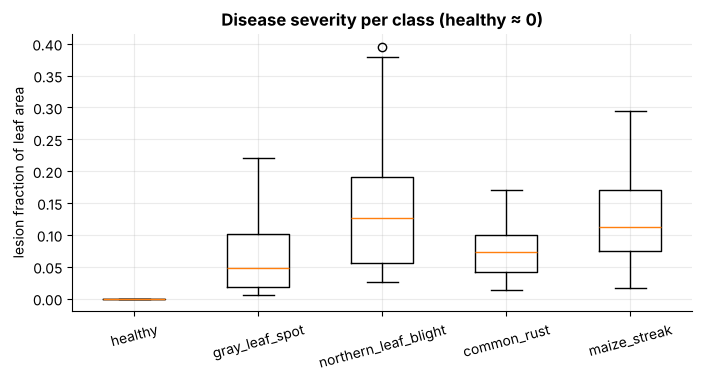

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot([d["lesion_train"][d["y_train"] == c] for c in range(5)])
ax.set_xticks(range(1, 6)); ax.set_xticklabels(names)
ax.set(ylabel="lesion fraction of leaf area", title="Disease severity per class (healthy ≈ 0)"); plt.xticks(rotation=15); plt.show()

🤔 **Pause and think.** Look at the *early-stage* images (small lesion fraction). Can *you* tell gray leaf spot from a healthy leaf with dust on it? What does that imply about the ceiling on accuracy?

<details><summary>Click to reveal the answer</summary>

Often not reliably: early infections are genuinely ambiguous, so **some error is irreducible**. Aiming for 100 % is unrealistic, and a good system must be honest about uncertainty (Section 9).

</details>

---
## 🧹 3. Preprocess: mind the channels!

In [4]:
# Our images are (N, H, W, 3) = channels LAST. PyTorch conv layers want (N, 3, H, W) = channels FIRST.
xt64 = d["x_train"].astype(np.float64)                                              # float64: summing 14 million float32 pixels loses precision!
mean, std = xt64.mean(axis=(0, 1, 2)), xt64.std(axis=(0, 1, 2))                  # one number PER COLOUR CHANNEL, from TRAIN only
print("per-channel mean:", mean.round(3), "std:", std.round(3))

def prep(a):
    return torch.tensor(((a - mean) / std).transpose(0, 3, 1, 2), dtype=torch.float32)

Xtr, Xval, Xte = prep(d["x_train"]), prep(d["x_val"]), prep(d["x_test"])
Ytr, Yval, Yte = (torch.tensor(d[k]) for k in ("y_train", "y_val", "y_test"))
print("tensor shapes:", tuple(Xtr.shape), tuple(Xval.shape), tuple(Xte.shape))
train_dl = DataLoader(TensorDataset(Xtr, Ytr), batch_size=64, shuffle=True)
val_dl = DataLoader(TensorDataset(Xval, Yval), batch_size=450)

per-channel mean: [0.339 0.359 0.222] std: [0.107 0.137 0.078]


tensor shapes: (2100, 3, 48, 48) (450, 3, 48, 48) (450, 3, 48, 48)


---
## 📏 4. Baselines: what can raw pixels do?

In [5]:
import warnings; warnings.filterwarnings("ignore")
from sklearn.linear_model import LogisticRegression
flat = lambda a: a.reshape(len(a), -1)
lr = LogisticRegression(max_iter=100).fit(flat(d["x_train"]), d["y_train"])
print(f"majority class                 : {np.mean(d['y_val'] == np.bincount(d['y_train']).argmax()):.1%}")
print(f"logistic regression on pixels  : {lr.score(flat(d['x_val']), d['y_val']):.1%}")

dl.set_seed(0)
mlp = nn.Sequential(nn.Flatten(), nn.Linear(3 * 48 * 48, 128), nn.ReLU(), nn.Linear(128, 5))
h_mlp = dl.fit(mlp, train_dl, val_dl, nn.CrossEntropyLoss(), torch.optim.Adam(mlp.parameters(), 1e-3), epochs=15, device=cpu, verbose=False)
print(f"ANN (fully connected, 886k params): val acc {h_mlp['val_acc'][-1]:.1%}   | train acc {h_mlp['train_acc'][-1]:.1%}  ← memorises, doesn't generalise")

majority class                 : 18.4%
logistic regression on pixels  : 30.2%


ANN (fully connected, 886k params): val acc 29.8%   | train acc 100.0%  ← memorises, doesn't generalise


> 💡 **Big idea**: The fully-connected ANN memorises the training set (≈100 % train accuracy) but generalises poorly: leaves appear **rotated at random** and lesions at random positions, so pixel-position-specific weights can't capture "brown rectangle *somewhere*". This is the CNN's home turf.

---
## 🧠 5. The CNN

Architecture: three **Conv → BatchNorm → ReLU → MaxPool** blocks (16 → 32 → 64 filters, halving the image each time: 48 → 24 → 12 → 6), then a classifier head.

**Augmentation for leaves.** A leaf has no "correct" orientation, so **rotating by 0/90/180/270° and flipping are label-preserving** (unlike colour changes toward yellow, which might fake *maize streak*). Every epoch the network sees the 8 orientations of each leaf.

CNN parameters: 35,333   (vs 886k for the ANN)


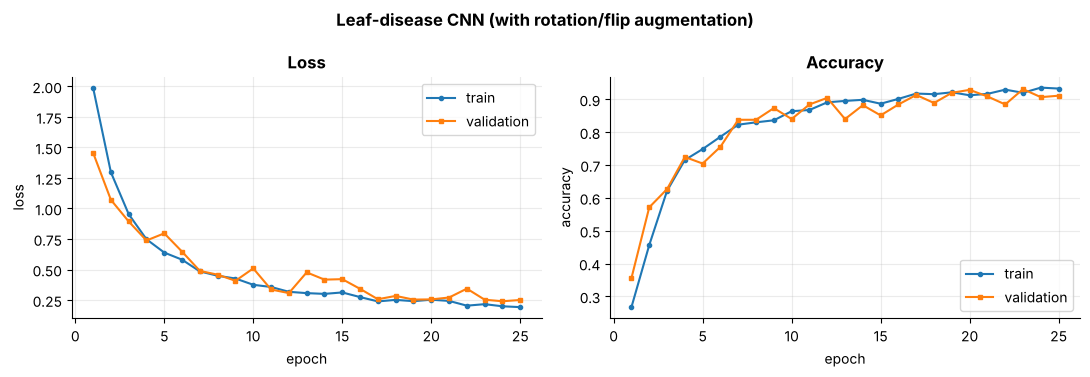

final: train acc 93.3% | val acc 91.1%  (65s)


In [6]:
def augment_leaf(xb):
    """Random 90° rotation + random flip, independently for each image in the batch."""
    out = []
    for x in xb:                                                           # x: (3, H, W)
        x = torch.rot90(x, int(torch.randint(0, 4, (1,))), dims=(1, 2))
        if torch.rand(1) < 0.5: x = x.flip(2)
        out.append(x)
    return torch.stack(out)

class AugLoader:
    def __init__(self, loader): self.loader = loader
    def __len__(self): return len(self.loader)
    def __iter__(self):
        for xb, yb in self.loader: yield augment_leaf(xb), yb

def block(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))

def make_leaf_cnn():
    dl.set_seed(0)
    return nn.Sequential(block(3, 16), block(16, 32), block(32, 64),       # 3×48×48 → 64×6×6
                         nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 6 * 6, 5))

cnn = make_leaf_cnn()
print("CNN parameters:", f"{dl.count_params(cnn):,}   (vs 886k for the ANN)")
history = dl.fit(cnn, AugLoader(train_dl), val_dl, nn.CrossEntropyLoss(), torch.optim.Adam(cnn.parameters(), 2e-3), epochs=25, device=cpu, verbose=False)
dl.plot_history(history, "Leaf-disease CNN (with rotation/flip augmentation)")
print(f"final: train acc {history['train_acc'][-1]:.1%} | val acc {history['val_acc'][-1]:.1%}  ({history['seconds']:.0f}s)")

---
## 🎯 6. Evaluate (test set, once)

🎯 TEST ACCURACY: 91.11%


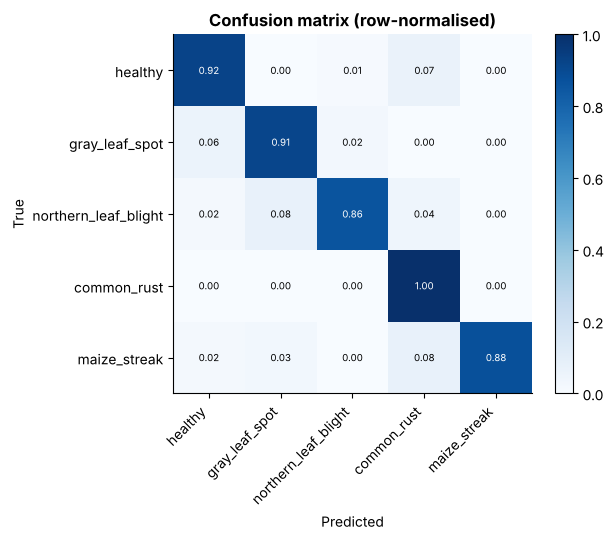

                      precision    recall  f1-score   support

             healthy      0.903     0.923     0.913        91
      gray_leaf_spot      0.882     0.915     0.898        82
northern_leaf_blight      0.964     0.860     0.909        93
         common_rust      0.816     1.000     0.899        80
        maize_streak      1.000     0.875     0.933       104

            accuracy                          0.911       450
           macro avg      0.913     0.915     0.911       450
        weighted avg      0.919     0.911     0.912       450



In [7]:
probs = dl.predict_proba(cnn, Xte, device=cpu); preds = probs.argmax(1).numpy(); y_te = d["y_test"]
print(f"🎯 TEST ACCURACY: {np.mean(preds == y_te):.2%}")
cm = dl.plot_confusion(y_te, preds, class_names=names, normalize=True, figsize=(6.5, 5.5))
from sklearn.metrics import classification_report
print(classification_report(y_te, preds, target_names=names, digits=3))

> 🇰🇪 **In the field**: Look at **recall** per disease (the fraction of *truly diseased* leaves we catch) and **which direction the mistakes go**. Missing a disease (predicting `healthy`) is the costly error for farmers. A model can have great overall accuracy and still be unacceptable if recall on *maize_streak* is poor.

---
## 📉 7. Severity analysis: where do the mistakes live?

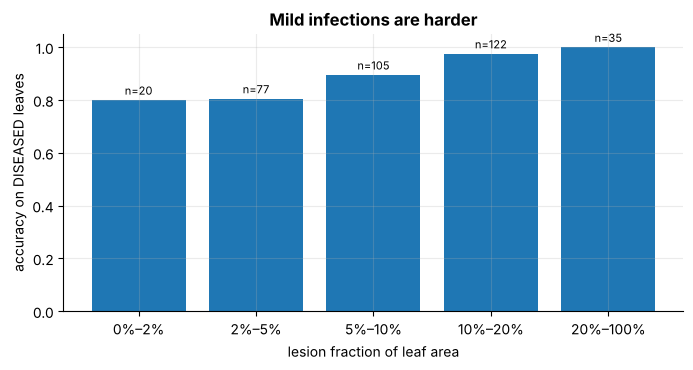

In [8]:
frac = d["lesion_test"]; correct = preds == y_te
diseased = y_te != 0
edges = np.array([0, 0.02, 0.05, 0.10, 0.20, 1.0])
labels = [f"{a:.0%}–{b:.0%}" for a, b in zip(edges[:-1], edges[1:])]
bin_id = np.digitize(frac[diseased], edges[1:-1])
acc_bins = [correct[diseased][bin_id == b].mean() if (bin_id == b).any() else np.nan for b in range(len(labels))]
n_bins = [(bin_id == b).sum() for b in range(len(labels))]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(labels, acc_bins); ax.set(ylim=(0, 1.05), xlabel="lesion fraction of leaf area", ylabel="accuracy on DISEASED leaves", title="Mild infections are harder")
for i, (a, n) in enumerate(zip(acc_bins, n_bins)): ax.text(i, (a if a == a else 0) + .02, f"n={n}", ha="center", fontsize=8)
plt.show()

The pattern is the practical story of disease detection: **mild, early infections are hardest: and they're exactly the ones where early action helps most.** This is why a model's headline accuracy can flatter it: test sets full of obvious cases hide failure on subtle ones.

40 test mistakes. Showing up to 16 (true→predicted):


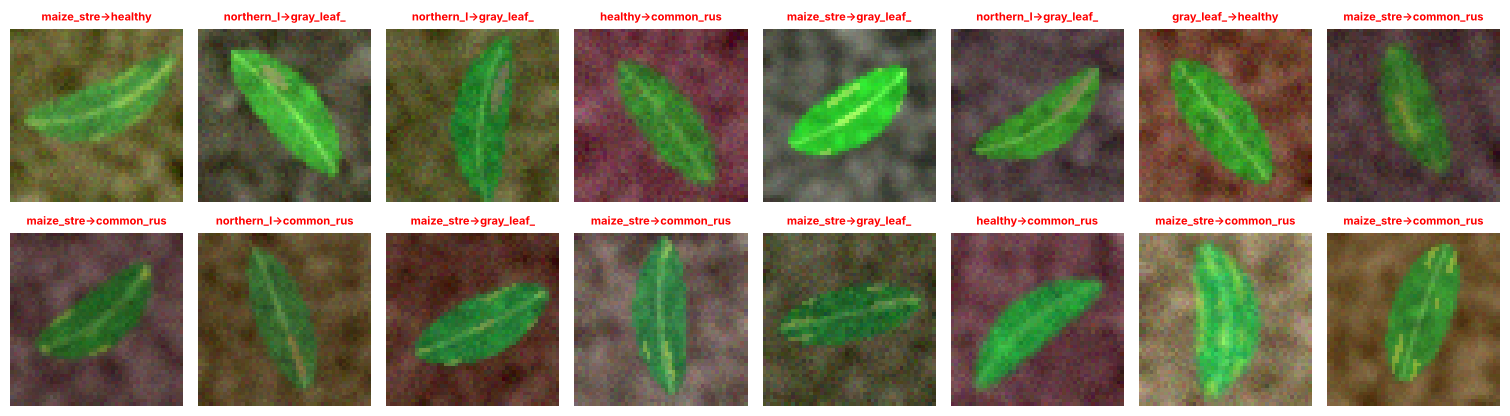

In [9]:
wrong = np.where(~correct)[0]
print(f"{len(wrong)} test mistakes. Showing up to 16 (true→predicted):")
x_show = d["x_test"][wrong[:16]]
dl.show_images(x_show, y_te[wrong[:16]], class_names=[n[:10] for n in names], preds=preds[wrong[:16]], n=16, ncols=8, figscale=1.9)

---
## 🔦 8. Where is the model looking? Occlusion sensitivity

Neural networks are often called black boxes, but we can poke them. **Occlusion sensitivity**: slide a grey patch across the image; at each position measure how much the model's confidence in the *true class* **drops**. Big drop = "this region mattered".

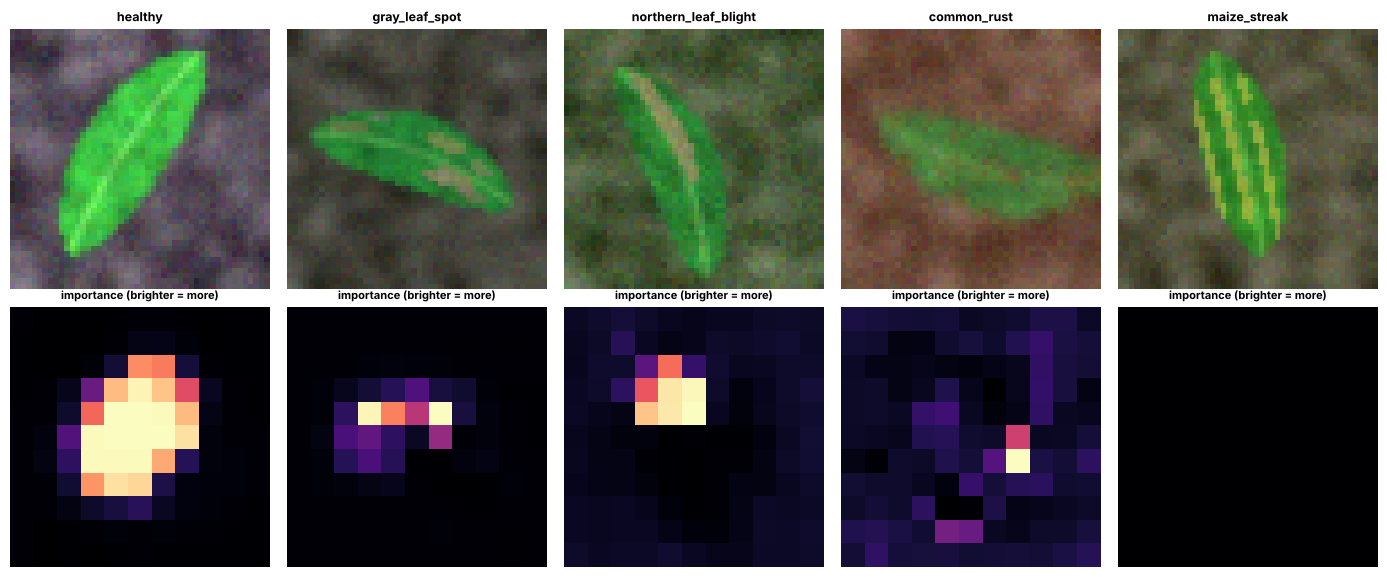

In [10]:
def occlusion_map(model, img, target, patch=8, stride=4):
    """img: (3,H,W) normalised tensor. Returns a map of probability DROP when each region is hidden."""
    model.eval(); _, H, W = img.shape
    with torch.no_grad():
        base = torch.softmax(model(img[None]), 1)[0, target].item()
        ys, xs = list(range(0, H - patch + 1, stride)), list(range(0, W - patch + 1, stride))
        heat = np.zeros((len(ys), len(xs)))
        for i, y in enumerate(ys):
            for j, x in enumerate(xs):
                occluded = img.clone(); occluded[:, y:y + patch, x:x + patch] = 0          # 0 = the mean colour after normalisation
                heat[i, j] = base - torch.softmax(model(occluded[None]), 1)[0, target].item()
    return heat

fig, axes = plt.subplots(2, 5, figsize=(14, 5.8))
for c in range(5):
    idx = np.where((y_te == c) & (preds == y_te) & (d["lesion_test"] > 0.03))[0] if c else np.where((y_te == c) & (preds == y_te))[0]
    i = idx[0]
    heat = occlusion_map(cnn, Xte[i], c)
    axes[0, c].imshow(d["x_test"][i]); axes[0, c].set_title(names[c], fontsize=9); axes[0, c].axis("off")
    axes[1, c].imshow(heat, cmap="magma"); axes[1, c].set_title("importance (brighter = more)", fontsize=8); axes[1, c].axis("off")
plt.tight_layout(); plt.show()

> 📝 **Note**: If a healthy leaf's heat-map lights up on the *background*, the model learned a shortcut. This is a famous real-world failure: a PlantVillage-trained classifier can partly identify diseases from the **background** of the lab photo, not the leaf. Always check what the model attends to.

---
## 🚦 9. A triage policy: diagnose, retake, or refer

A confident wrong answer is dangerous; an honest *"I'm not sure"* is useful. Using the model's confidence (max probability) we define a **three-tier policy**:

| Confidence | App behaviour |
|:--|:--|
| **≥ 0.90** | ✅ Show diagnosis + advice |
| **0.60 – 0.90** | 📷 "Not sure: retake the photo (better light, one leaf, fill the frame). Top guesses: …" |
| **< 0.60** | 👩‍🌾 "Please consult your extension officer" |

*Evaluate the policy, not just the model:*

diagnose : 338 leaves (75.1%) | accuracy of the model's guess on these: 98.5%
retake   :  81 leaves (18.0%) | accuracy of the model's guess on these: 72.8%
refer    :  31 leaves ( 6.9%) | accuracy of the model's guess on these: 58.1%


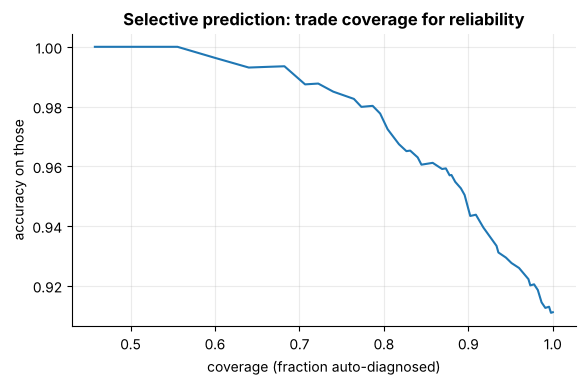

In [11]:
conf = probs.max(1).values.numpy()
tiers = np.where(conf >= 0.90, "diagnose", np.where(conf >= 0.60, "retake", "refer"))
for t in ["diagnose", "retake", "refer"]:
    m = tiers == t
    print(f"{t:9s}: {m.sum():3d} leaves ({m.mean():5.1%}) | accuracy of the model's guess on these: {correct[m].mean() if m.any() else float('nan'):.1%}")

ts = np.linspace(0.3, 0.999, 60)
cov = [(conf >= t).mean() for t in ts]; acc = [correct[conf >= t].mean() if (conf >= t).any() else np.nan for t in ts]
plt.figure(figsize=(6.5, 3.8)); plt.plot(cov, acc); plt.xlabel("coverage (fraction auto-diagnosed)"); plt.ylabel("accuracy on those")
plt.title("Selective prediction: trade coverage for reliability"); plt.show()

---
## 🌍 10. Toward the real world: transfer learning & real data

With real photos you'll rarely train from scratch. **Transfer learning** reuses a network already trained on ImageNet (1.2 M photos): its early layers detect edges/textures useful for *any* image. You replace the final layer and fine-tune. (Not executed here because it downloads pretrained weights; run it on your own machine.)

```python
import torch, torch.nn as nn
from torchvision import models, datasets, transforms

# 1. Real data: one sub-folder per class  (e.g. PlantVillage maize folders)  →  ImageFolder
tfm = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(), transforms.RandomRotation(30),
                          transforms.ColorJitter(0.2, 0.2, 0.1), transforms.ToTensor(),
                          transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
train_ds = datasets.ImageFolder("data/maize/train", transform=tfm)

# 2. Pretrained backbone, new head
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters(): p.requires_grad = False            # freeze the backbone (stage 1)
model.fc = nn.Linear(model.fc.in_features, len(train_ds.classes))   # trainable new classifier
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
# ... train with dl.fit(...); then unfreeze everything and fine-tune with lr=1e-4 (stage 2)
```

**Real-data checklist** 📝
* **PlantVillage** has maize classes (gray leaf spot, northern leaf blight, common rust, healthy) but was photographed on **plain lab backgrounds** → models look great there and often fall apart in the field. Other datasets with field-condition photos exist (search for field-collected maize disease sets); *maize streak virus* is under-represented in the big public collections.
* **Collect your own** field photos with the cooperative (different phones, light, growth stages) and label with an agronomist. Even 50–100 images per class *in your real conditions* often beats thousands of lab images.
* **Split by farm/field/session**, not by random image: neighbouring photos from the same leaf leak information across train and test.
* Track **per-class recall**, **calibration**, and performance **per phone model/lighting**.

---
## 📝 11. Report & stretch goals

| Item | Your entry |
|:--|:--|
| Problem, users, cost of each error type | |
| Data (source, size, split, **synthetic caveat**) | |
| Baselines (majority, logistic reg., ANN) | |
| Final model & augmentation rationale | CNN 3 blocks, rot90+flip |
| Test accuracy & per-class recall | |
| Severity analysis (accuracy on mild infections) | |
| Occlusion findings | |
| Triage policy & its coverage/accuracy | |
| **Bias, limitations, and what would break in the field** | |
| Next steps (real data, transfer learning, per-device evaluation) | |

### 🚀 Stretch goals
1. **Test-time augmentation (TTA):** average the model's probabilities over the 8 rotated/flipped versions of each test image. Does accuracy (or calibration) improve?
2. **Class imbalance:** subsample *maize_streak* to 10 % of the training set. How does its recall collapse? Fix it with class weights (`nn.CrossEntropyLoss(weight=...)`) or oversampling.
3. **Robustness:** evaluate on blurred / darker / noisier test images. Which class suffers first? Add matching augmentation and re-test.
4. **Smaller is better:** shrink the CNN to <10k parameters. How low can you go while keeping ≥ 90 % accuracy? (Think: a phone with no internet.)
5. **Calibration:** plot a reliability diagram (confidence bins vs accuracy). Try label smoothing or temperature scaling.

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 10.1: Per-channel normalisation  &nbsp; `⭐`

Write `channel_stats(x)` returning `(mean, std)`: each an array of length 3: for images `x` of shape `(N, H, W, 3)`, and `normalise(x, mean, std)` returning the **channels-first** float32 tensor `(N, 3, H, W)` of standardised images.

<details><summary>💡 Hint 1</summary>

`x.mean(axis=(0, 1, 2))` averages over everything except the channel axis.

</details>

<details><summary>💡 Hint 2</summary>

Standardise with broadcasting `(x - mean) / std`, then `.transpose(0, 3, 1, 2)` to move channels.

</details>

<details><summary>💡 Hint 3</summary>

`torch.tensor(arr, dtype=torch.float32)`.

</details>


In [ ]:
def channel_stats(x):
    pass

def normalise(x, mean, std):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
rng = np.random.default_rng(0); x = rng.uniform(0, 1, (50, 8, 8, 3)) * np.array([1, 2, 3])
r = channel_stats(x)
dl.check("mean has 3 entries, matching the data", r is not None and np.allclose(r[0], x.mean((0, 1, 2))))
z = normalise(x, *r) if r is not None else None
dl.check("output shape is (50, 3, 8, 8), float32", z is not None and tuple(z.shape) == (50, 3, 8, 8) and z.dtype == torch.float32)
dl.check("each channel now has mean≈0, std≈1", z is not None and torch.allclose(z.mean((0, 2, 3)), torch.zeros(3), atol=1e-5) and torch.allclose(z.std((0, 2, 3), unbiased=False), torch.ones(3), atol=1e-4))

---
### 🧩 Problem 10.2: Dihedral augmentation  &nbsp; `⭐⭐`

Write `rot_flip(x, k, flip)` for a batch `x` of shape `(N, C, H, W)`: rotate by `k × 90°` in the spatial plane, then (if `flip`) flip horizontally. Use `torch.rot90` and `Tensor.flip`. Then write `all_8(x)` returning a list of the 8 distinct orientations (k = 0..3 × flip ∈ {False, True}).

<details><summary>💡 Hint 1</summary>

`torch.rot90(x, k, dims=(2, 3))`

</details>

<details><summary>💡 Hint 2</summary>

`x.flip(3)` flips the width axis.

</details>

<details><summary>💡 Hint 3</summary>

`[rot_flip(x, k, f) for k in range(4) for f in (False, True)]`

</details>


In [ ]:
def rot_flip(x, k, flip):
    pass

def all_8(x):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
x = torch.arange(2 * 3 * 4 * 4, dtype=torch.float32).reshape(2, 3, 4, 4)
dl.check("rotating 4 times returns the original", rot_flip(x, 4, False) is not None and torch.equal(rot_flip(x, 4, False), x))
dl.check("rot90 of a (4,4) map matches numpy", rot_flip(x, 1, False) is not None and np.array_equal(rot_flip(x, 1, False)[0, 0].numpy(), np.rot90(x[0, 0].numpy())))
views = all_8(x)
dl.check("8 views", views is not None and len(views) == 8)
dl.check("all 8 views are different", views is not None and len({v[0, 0].numpy().tobytes() for v in views}) == 8)

---
### 🧩 Problem 10.3: Test-time augmentation  &nbsp; `⭐⭐⭐`

Write `tta_predict(model, x)`: average the **softmax probabilities** of `model` over all 8 orientations of the batch `x` `(N, 3, H, W)` (rotations by 0–270° × optional flip) and return the averaged `(N, num_classes)` probabilities.
Run the model in `eval` mode with gradients off. *(Helper `rot_flip` is provided.)*

<details><summary>💡 Hint 1</summary>

Loop over `k in range(4)` and `flip in (False, True)`; accumulate `torch.softmax(model(view), 1)`.

</details>

<details><summary>💡 Hint 2</summary>

Divide the sum by 8 at the end.

</details>

<details><summary>💡 Hint 3</summary>

Wrap in `with torch.no_grad():` and call `model.eval()` first.

</details>


In [ ]:
def rot_flip(x, k, flip):
    x = torch.rot90(x, k, dims=(2, 3))
    return x.flip(3) if flip else x

def tta_predict(model, x):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
# A model built only from global-average pooling is exactly invariant to rotations & flips → TTA must equal plain prediction.
inv = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(3, 4)); inv.eval()
x = torch.randn(5, 3, 8, 8)
out = tta_predict(inv, x)
dl.check("output shape (5, 4), rows sum to 1", out is not None and tuple(out.shape) == (5, 4) and torch.allclose(out.sum(1), torch.ones(5), atol=1e-5))
dl.check("invariant model → TTA equals plain softmax", out is not None and torch.allclose(out, torch.softmax(inv(x), 1), atol=1e-5))
# A model that is NOT invariant should change:
non_inv = nn.Sequential(nn.Flatten(), nn.Linear(3 * 8 * 8, 4)); non_inv.eval()
o2 = tta_predict(non_inv, x)
dl.check("non-invariant model → TTA differs from plain prediction", o2 is not None and not torch.allclose(o2, torch.softmax(non_inv(x), 1), atol=1e-3))

---
### 🧩 Problem 10.4: Accuracy by severity bin  &nbsp; `⭐⭐`

Write `accuracy_by_bin(correct, values, edges)` where `correct` is a boolean array, `values` the per-sample quantity (e.g. lesion fraction) and `edges` the interior bin boundaries (so `k` edges make `k+1` bins). Return a list with the mean of `correct` in each bin (`nan` for empty bins).

<details><summary>💡 Hint 1</summary>

`np.digitize(values, edges)` returns the bin index 0..len(edges) for every value.

</details>

<details><summary>💡 Hint 2</summary>

For each bin `b`: `correct[bins == b].mean()` if any element is in the bin.

</details>


In [ ]:
def accuracy_by_bin(correct, values, edges):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
correct = np.array([0, 0, 1, 1, 1, 1], bool); vals = np.array([0.01, 0.02, 0.06, 0.07, 0.3, 0.4])
r = accuracy_by_bin(correct, vals, [0.05, 0.2, 0.5])
dl.check("three populated bins + one empty", r is not None and len(r) == 4)
dl.check("bin 0 accuracy 0.0, bin 1 accuracy 1.0, bin 2 accuracy 1.0", r is not None and r[:3] == [0.0, 1.0, 1.0])
dl.check("empty bin gives NaN", r is not None and np.isnan(r[3]))

---
### 🧩 Problem 10.5: Triage the predictions  &nbsp; `⭐⭐`

Write `triage(probs, hi=0.9, lo=0.6)` for a `(N, C)` probability array. Return a dict with the **number** of cases in each tier (`"diagnose"` (max prob ≥ hi), `"retake"` (lo ≤ max prob < hi), `"refer"` (< lo)) which must sum to N.

<details><summary>💡 Hint 1</summary>

`conf = probs.max(axis=1)`.

</details>

<details><summary>💡 Hint 2</summary>

Count with boolean masks: `(conf >= hi).sum()`, `((conf >= lo) & (conf < hi)).sum()`, `(conf < lo).sum()`.

</details>

<details><summary>💡 Hint 3</summary>

Cast counts to `int` for a clean dict.

</details>


In [ ]:
def triage(probs, hi=0.9, lo=0.6):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
p = np.array([[.95, .05], [.7, .3], [.55, .45], [.9, .1], [.6, .4]])
dl.check("{'diagnose': 2, 'retake': 2, 'refer': 1}", triage(p) == {"diagnose": 2, "retake": 2, "refer": 1})
dl.check("stricter thresholds shift cases down", triage(p, hi=0.99) == {"diagnose": 0, "retake": 4, "refer": 1})

---
### 🧩 Problem 10.6: Occlusion map (challenge)  &nbsp; `⭐⭐⭐`

Write `occlusion_map(model, img, target, patch=8, stride=4)` returning a 2-D NumPy array: entry `(i, j)` is the **drop in the softmax probability of `target`** when the patch of size `patch × patch` at row `i·stride`, column `j·stride` is replaced with zeros.
Output shape = `((H−patch)//stride + 1, (W−patch)//stride + 1)`.

<details><summary>💡 Hint 1</summary>

First compute the base probability with the un-occluded image (`img[None]` adds the batch axis).

</details>

<details><summary>💡 Hint 2</summary>

Loop over row/column start positions; copy the image (`img.clone()`), zero the patch, re-predict.

</details>

<details><summary>💡 Hint 3</summary>

heat[i, j] = base − occluded_probability. Use `torch.no_grad()` and `model.eval()`.

</details>


In [ ]:
def occlusion_map(model, img, target, patch=8, stride=4):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
class CenterModel(nn.Module):
    def forward(self, x):                       # confidence in class 1 depends ONLY on the centre 16×16 region
        c = x[:, :, 8:24, 8:24].mean(dim=(1, 2, 3)) * 5
        return torch.stack([-c, c], dim=1)
m = CenterModel(); img = torch.ones(3, 32, 32)
h = occlusion_map(m, img, 1, patch=8, stride=4)
dl.check("shape is 7×7", h is not None and h.shape == (7, 7))
dl.check("corner patches don't matter (≈0 drop)", h is not None and abs(h[0, 0]) < 1e-6 and abs(h[-1, -1]) < 1e-6)
dl.check("the biggest drop is in the central region", h is not None and 2 <= np.unravel_index(h.argmax(), h.shape)[0] <= 4 and 2 <= np.unravel_index(h.argmax(), h.shape)[1] <= 4)

---
## 🏁 Key takeaways
- ✅ Convert **channels-last → channels-first**, normalise **per channel** with train-only statistics.
- ✅ A **CNN with label-preserving augmentation** (rot90 + flip) crushes an ANN on randomly-oriented leaves, with a fraction of the parameters.
- ✅ Overall accuracy hides weakness: analyse **per-class recall** and **accuracy vs severity**: mild infections are the hard (and valuable) cases.
- ✅ **Occlusion sensitivity** reveals what the model uses: look out for shortcuts like backgrounds.
- ✅ Deploy with a **triage policy** (diagnose / retake / refer): honest uncertainty beats confident errors.
- ✅ Real deployment demands **real field data, transfer learning, per-device testing, and humility** about distribution shift.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** Why is a 90-degree rotation a valid augmentation for leaf images but not for handwritten digits?

<details><summary>Answer</summary>

A leaf photo has no canonical 'up': the same disease looks the same rotated. A '6' rotated 180° becomes a '9': the label changes, so the transform isn't label-preserving.

</details>

**Q2.** Your model has 96 % accuracy on a test set where 90 % of leaves are healthy. Why isn't that impressive?

<details><summary>Answer</summary>

A model that always says 'healthy' gets 90 %. Look at per-class recall/precision (especially for diseases) and baselines.

</details>

**Q3.** Why split train/test by *field* instead of by random image?

<details><summary>Answer</summary>

Photos from the same field/leaf are near-duplicates; random splitting leaks them across sets and inflates the test score. Splitting by field measures generalisation to *new* places.

</details>

**Q4.** What does it mean if the occlusion map for a healthy leaf highlights the background?

<details><summary>Answer</summary>

The model may be using background cues (a shortcut) rather than leaf health: it will fail when backgrounds change.

</details>

---
## 📚 Go deeper (optional)
- Mohanty, Hughes & Salathé (2016) (*Using Deep Learning for Image-Based Plant Disease Detection* (the PlantVillage paper)) and later papers on its limitations in the field
- Geirhos et al. (2020): *Shortcut learning in deep neural networks*
- Fast.ai: *Practical Deep Learning for Coders*, transfer-learning chapters
- CIMMYT / KALRO / PlantVillage Nuru app: real-world mobile crop-diagnosis efforts in Africa

---
⬅️ Previous: [09 · Project 2 · Image Classification](09_project2_image_classification.ipynb) &nbsp;|&nbsp; Next: [11 · Recurrent Networks: RNN, LSTM & GRU](11_rnn_lstm_gru.ipynb) ➡️